# 03 — RFM customer segmentation

**Question:** who are Olist's customers, in terms of how recently, how often and how much they buy — and which segments deserve investment?

**Method:** RFM scores each customer (`customer_unique_id`) on
- **Recency** — days since their last delivered order, measured from the dataset's last order date (not "today": the data ends in 2018);
- **Frequency** — number of delivered orders;
- **Monetary** — total payment value across those orders.

Each dimension is scored 1–5 (5 = best) and the scores are mapped to named segments.

**Why quantile scoring?** It is distribution-free and easy to explain: a score of 5 on Monetary means "top 20% of spenders". The catch on this dataset is Frequency: ~97% of customers have exactly one order, so quantiles collapse. We therefore score Frequency with fixed thresholds (1 order → 1, 2 → 3, 3 → 4, 4+ → 5) and keep quantiles for R and M. This is a deliberate adaptation and is logged in `docs/decision_log.md`.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from viz_style import *

P = Path("../data/processed")
orders    = pd.read_csv(P / "orders.csv", parse_dates=["order_purchase_timestamp"])
customers = pd.read_csv(P / "customers.csv")
pay       = pd.read_csv(P / "order_payments_summary.csv")

# Delivered orders only — an unpaid or cancelled order is not a purchase
df = (orders[orders.is_delivered]
        .merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id")
        .merge(pay[["order_id", "payment_total"]], on="order_id", how="left"))
snapshot = df.order_purchase_timestamp.max() + pd.Timedelta(days=1)
print(f"{len(df):,} delivered orders, {df.customer_unique_id.nunique():,} customers, snapshot date {snapshot.date()}")

96,478 delivered orders, 93,358 customers, snapshot date 2018-08-30


## 1. Compute R, F, M per customer

In [2]:
rfm = (df.groupby("customer_unique_id")
         .agg(last_order=("order_purchase_timestamp", "max"),
              first_order=("order_purchase_timestamp", "min"),
              frequency=("order_id", "nunique"),
              monetary=("payment_total", "sum"),
              state=("customer_state", "first"))
         .reset_index())
rfm["recency"] = (snapshot - rfm.last_order).dt.days
rfm[["recency", "frequency", "monetary"]].describe(percentiles=[.5, .8, .95, .99]).round(1)

,recency,frequency,monetary
count,93358.0,93358.0,93358.0
mean,237.9,1.0,165.2
std,152.6,0.2,226.3
min,1.0,1.0,0.0
50%,219.0,1.0,107.8
80%,382.0,1.0,208.6
95%,520.0,1.0,469.6
99%,575.0,2.0,1097.1
max,714.0,15.0,13664.1


In [3]:
print("Frequency distribution — why quantile scoring fails for F:")
rfm.frequency.value_counts().sort_index().head(8).to_frame("customers").assign(pct=lambda d: (100*d.customers/len(rfm)).round(2))

Frequency distribution — why quantile scoring fails for F:


,customers,pct
frequency,,
1,90557,97.00
2,2573,2.76
3,181,0.19
4,28,0.03
5,9,0.01
6,5,0.01
7,3,0.00
9,1,0.00


## 2. Score 1–5

R and M by quintile (lower recency = better = 5). F by fixed thresholds because of the one-order mass.

In [4]:
rfm["R"] = pd.qcut(rfm.recency, 5, labels=[5, 4, 3, 2, 1]).astype(int)          # recent -> 5
rfm["M"] = pd.qcut(rfm.monetary.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["F"] = pd.cut(rfm.frequency, bins=[0, 1, 2, 3, np.inf], labels=[1, 3, 4, 5]).astype(int)
rfm["RFM"] = rfm.R.astype(str) + rfm.F.astype(str) + rfm.M.astype(str)
rfm[["R", "F", "M"]].apply(pd.Series.value_counts).fillna(0).astype(int).sort_index()

,R,F,M
1,18639,90557,18672
2,18577,0,18671
3,18709,2573,18672
4,18705,181,18671
5,18728,47,18672


## 3. Map scores to segments

Rules (checked top to bottom, first match wins). They follow the standard RFM grid, adapted so that *any* repeat purchase is treated as a loyalty signal — in a marketplace with 3% repeat rate, a second order is rare and valuable.

| Segment | Rule | Business meaning |
|---|---|---|
| Champions | F ≥ 4 and R ≥ 4 | Bought 3+ times, recently. Protect and reward. |
| Loyal | F ≥ 3 and R ≥ 3 | Repeat buyers, still active. Upsell. |
| At Risk | F ≥ 3 and R ≤ 2 | Were repeat buyers, gone quiet. Win back now. |
| Potential Loyalist | F = 1, R ≥ 4, M ≥ 4 | One recent big order. Convert to a second purchase. |
| New | F = 1, R = 5 | Bought in the most recent window. Onboard. |
| Promising | F = 1, R ≥ 3 | Single moderately recent order. Nurture. |
| Hibernating | F = 1, R = 2 | One order, a long time ago. Low-cost reactivation. |
| Lost | F = 1, R = 1 | One order, longest ago. Do not spend on them. |

In [5]:
def segment(r):
    if r.F >= 4 and r.R >= 4:               return "Champions"
    if r.F >= 3 and r.R >= 3:               return "Loyal"
    if r.F >= 3 and r.R <= 2:               return "At Risk"
    if r.R >= 4 and r.M >= 4:               return "Potential Loyalist"
    if r.R == 5:                            return "New"
    if r.R >= 3:                            return "Promising"
    if r.R == 2:                            return "Hibernating"
    return "Lost"

rfm["segment"] = rfm.apply(segment, axis=1)
ORDER = ["Champions", "Loyal", "At Risk", "Potential Loyalist", "New", "Promising", "Hibernating", "Lost"]

summary = (rfm.groupby("segment")
              .agg(customers=("customer_unique_id", "size"), revenue=("monetary", "sum"),
                   avg_recency_days=("recency", "mean"), avg_orders=("frequency", "mean"), avg_spend=("monetary", "mean"))
              .reindex(ORDER))
summary["pct_customers"] = 100 * summary.customers / summary.customers.sum()
summary["pct_revenue"]   = 100 * summary.revenue / summary.revenue.sum()
summary["revenue_index"] = (summary.pct_revenue / summary.pct_customers).round(2)   # >1 = punches above its weight
summary.round(1)

,customers,revenue,avg_recency_days,avg_orders,avg_spend,pct_customers,pct_revenue,revenue_index
segment,,,,,,,,
Champions,122,67584.9,90.0,3.5,554.0,0.1,0.4,3.4
Loyal,1691,507958.3,135.0,2.0,300.4,1.8,3.3,1.8
At Risk,988,288814.0,382.3,2.1,292.3,1.1,1.9,1.8
Potential Loyalist,14446,4364648.6,91.6,1.0,302.1,15.5,28.3,1.8
New,10914,793317.6,44.8,1.0,72.7,11.7,5.1,0.4
Promising,28969,3535036.2,188.5,1.0,122.0,31.0,22.9,0.7
Hibernating,18024,2953904.5,316.3,1.0,163.9,19.3,19.2,1.0
Lost,18204,2911197.7,473.6,1.0,159.9,19.5,18.9,1.0


## 4. Visualise

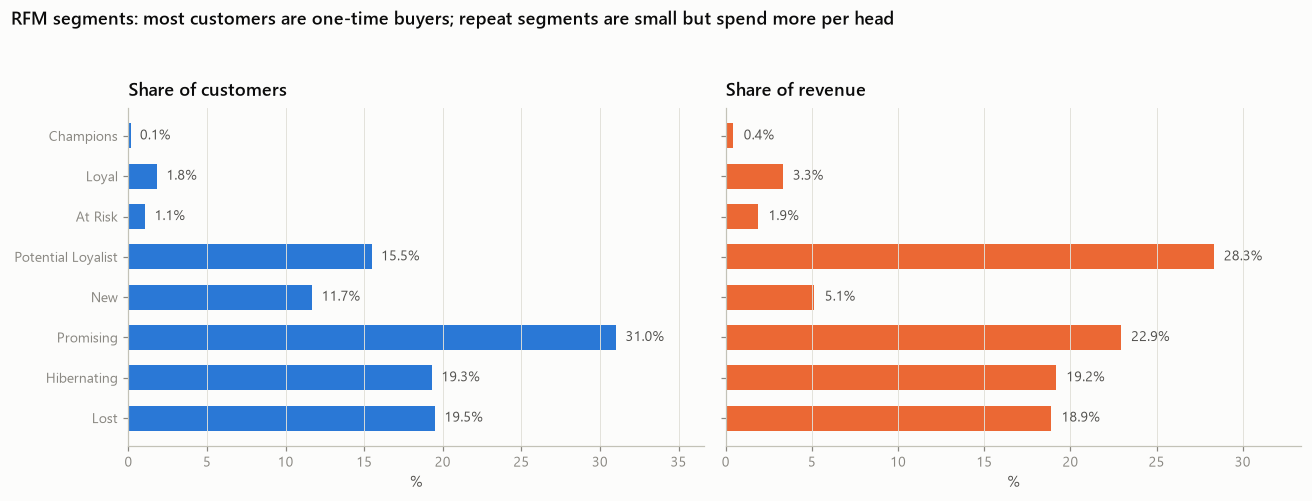

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
y = np.arange(len(ORDER))[::-1]
for ax, col, title, colour in [(axes[0], "pct_customers", "Share of customers", BLUE),
                               (axes[1], "pct_revenue",   "Share of revenue",   ORANGE)]:
    vals = summary[col].values
    ax.barh(y, vals, color=colour, height=0.62)
    for yi, v in zip(y, vals):
        ax.text(v + 0.6, yi, f"{v:.1f}%", va="center", fontsize=9, color=INK2)
    ax.set_yticks(y); ax.set_yticklabels(ORDER)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_xlim(0, max(vals) * 1.18)
    finish(ax, title, xlabel="%")
fig.suptitle("RFM segments: most customers are one-time buyers; repeat segments are small but spend more per head",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
plt.tight_layout(rect=[0, 0, 1, 0.94]); save(fig, "03_rfm_segments"); plt.show()

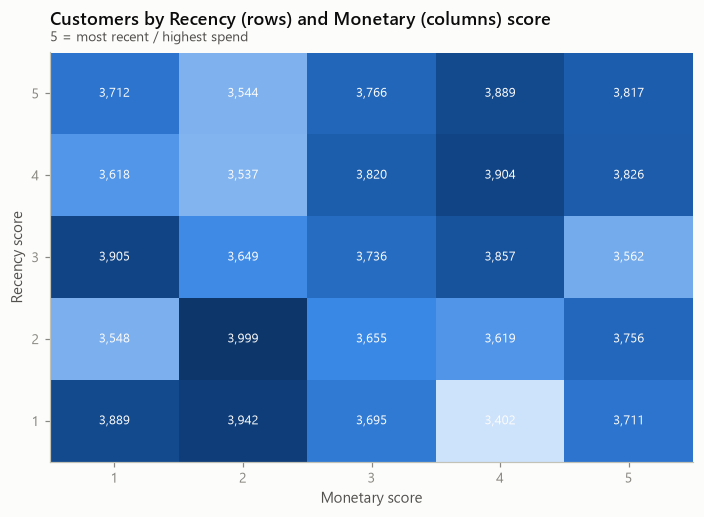

In [7]:
# Recency x Monetary heat map (counts) — where the mass of customers sits
pivot = rfm.pivot_table(index="R", columns="M", values="customer_unique_id", aggfunc="count").sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
im = ax.imshow(pivot.values, cmap=CMAP_SEQ, aspect="auto")
ax.set_xticks(range(5)); ax.set_xticklabels(pivot.columns); ax.set_yticks(range(5)); ax.set_yticklabels(pivot.index)
for i in range(5):
    for j in range(5):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8.5, color=INK if v < pivot.values.max()*0.6 else SURFACE)
ax.grid(False); finish(ax, "Customers by Recency (rows) and Monetary (columns) score", "5 = most recent / highest spend",
                       ylabel="Recency score", xlabel="Monetary score")
plt.tight_layout(); save(fig, "03_rfm_heatmap"); plt.show()

## 5. Export for Power BI and later notebooks

In [8]:
rfm_out = rfm[["customer_unique_id", "state", "recency", "frequency", "monetary", "R", "F", "M", "RFM", "segment", "first_order", "last_order"]]
rfm_out.to_csv(P / "rfm_segments.csv", index=False)
summary.round(2).to_csv(P / "rfm_segment_summary.csv")
print(rfm_out.shape, "->", P / "rfm_segments.csv")

(93358, 12) -> ..\data\processed\rfm_segments.csv


In [9]:
# Numbers for the write-up
repeaters = summary.loc[["Champions", "Loyal", "At Risk"]]
print(f"Repeat-buyer segments: {repeaters.customers.sum():,} customers = {repeaters.pct_customers.sum():.1f}% of customers, "
      f"{repeaters.pct_revenue.sum():.1f}% of revenue; avg spend R${repeaters.revenue.sum()/repeaters.customers.sum():,.0f} "
      f"vs R${summary.loc[['Lost','Hibernating','Promising','New'], 'revenue'].sum()/summary.loc[['Lost','Hibernating','Promising','New'], 'customers'].sum():,.0f} for one-time buyers")
print(f"Potential Loyalists: {summary.loc['Potential Loyalist','customers']:,} customers, {summary.loc['Potential Loyalist','pct_revenue']:.1f}% of revenue, "
      f"avg spend R${summary.loc['Potential Loyalist','avg_spend']:,.0f}")
print(f"Lost + Hibernating: {summary.loc[['Lost','Hibernating'],'pct_customers'].sum():.1f}% of customers, "
      f"{summary.loc[['Lost','Hibernating'],'pct_revenue'].sum():.1f}% of revenue")

Repeat-buyer segments: 2,801 customers = 3.0% of customers, 5.6% of revenue; avg spend R$309 vs R$134 for one-time buyers
Potential Loyalists: 14,446 customers, 28.3% of revenue, avg spend R$302
Lost + Hibernating: 38.8% of customers, 38.0% of revenue


## So what

*(Numbers are produced by the cells above — re-run to refresh.)*

- **Olist's base is overwhelmingly one-time buyers.** Only the three repeat segments (Champions, Loyal, At Risk) contain customers who have ever come back, and together they are a low-single-digit share of customers. Growth has come from acquisition, not retention.
- **Repeat buyers are worth several times a one-time buyer** in lifetime spend, so even a small improvement in second-purchase conversion compounds. The *Potential Loyalist* segment — recent, high-value, single order — is the cheapest group to convert.
- **Nearly 40% of the base is Lost or Hibernating** — one order, 10+ months ago, with a revenue index of 1.0 (they spent exactly their fair share, no more). Broad reactivation campaigns to them would burn budget. Target by segment instead.
- **Note on "New":** because Potential Loyalist is matched first, "New" holds only recent *low-spend* first orders, which is why its average spend is lowest. That is intentional: the high-spend recent buyers are the ones worth a dedicated play.

**Recommended actions**

| Segment | Action |
|---|---|
| Champions / Loyal | Early access and loyalty perks; ask for reviews and referrals — they are also the highest-rated experience. |
| At Risk | Time-boxed win-back offer within 30 days; investigate whether their last order was late (see notebook 05). |
| Potential Loyalist | Post-delivery follow-up with a category-matched recommendation and free-shipping-on-second-order voucher. |
| New / Promising | Onboarding email sequence; ensure first delivery is on time — the second purchase hinges on it. |
| Hibernating / Lost | Suppress from paid campaigns; one low-cost reactivation email per quarter at most. |